# 1. Building an Expected Threat (xT) model

**Question:** how much does moving the ball from one part of the pitch to another raise a team's chance of scoring?

Expected Threat ([Karun Singh, 2018](https://karun.in/blog/expected-threat.html)) answers this by giving every zone of the pitch a value: the probability that a possession currently in that zone ends in a goal within the next few actions. A pass or carry that moves the ball from zone *a* to zone *b* is credited with **xT(b) − xT(a)**. That gives credit to the passes and dribbles that set up a chance, which xG (shots only) never sees.

This notebook fits the model on all 655k passes, carries and shots of the 2015/16 Premier League season and checks that the result makes footballing sense.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from epl_xt import config
from epl_xt.pipeline import fit_xt_model
from epl_xt.plotting import SERIES, TEXT_SECONDARY, apply_style, pitch_heatmap, save
from epl_xt.xthreat import ExpectedThreat

apply_style()
pd.set_option("display.precision", 3)

actions = pd.read_parquet(config.ACTIONS_TABLE)
players = pd.read_parquet(config.PLAYER_SEASON_TABLE)
print(f"{len(actions):,} actions from {actions['match_id'].nunique()} matches")
actions["type"].value_counts()

655,476 actions from 380 matches


type
Pass     368619
Carry    276949
Shot       9908
Name: count, dtype: int64

## The model

The pitch is divided into a 16 × 12 grid (7.5 × 6.7 yard zones). From the season's data, each zone *z* gets four estimates:

| term | meaning |
|---|---|
| $s(z)$ | probability the player in possession shoots |
| $g(z)$ | average xG of a shot from *z* |
| $m(z) = 1 - s(z)$ | probability they pass or carry instead |
| $T(z, k)$ | probability a move from *z* **successfully** reaches zone *k* |

xT is the fixed point of

$$xT(z) = s(z)\,g(z) + m(z) \sum_k T(z,k)\,xT(k)$$

which is solved by iterating from xT = 0. Each iteration adds one more action of look-ahead. A few design choices:

* **Fit on the whole season.** Each zone's value pools roughly 3,400 actions (655k across 192 zones).
* **Failed moves are in the denominator of T but not the numerator.** Losing the ball is what drags a zone's value down.
* **Open play only.** Penalties (0.76 xG from one spot) and set-piece restarts would distort the zones they start from.
* **StatsBomb xG as the shot payoff** rather than raw goal rate, which is a lower-variance estimate of finishing chance.

Converged in 52 iterations


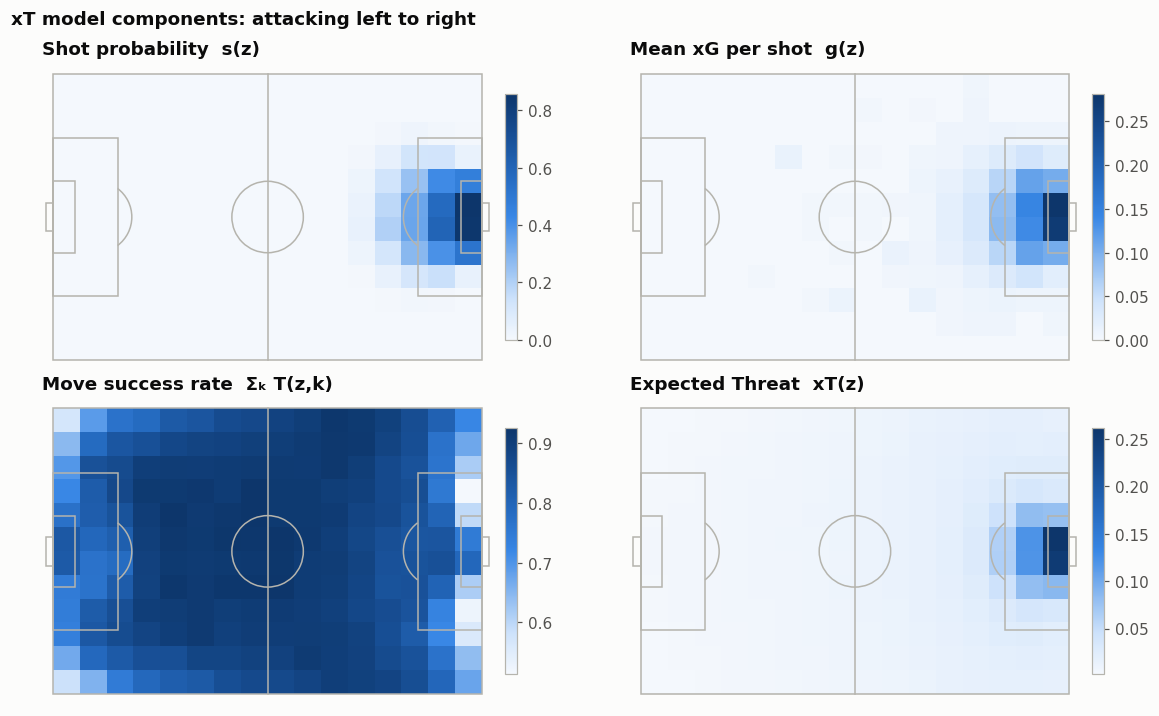

In [2]:
model = fit_xt_model(actions)
print(f"Converged in {model.n_iter_} iterations")

fig, axes = plt.subplots(2, 2, figsize=(11, 6.6))
panels = [
    (model.shot_prob_, "Shot probability  s(z)", "{:.2f}"),
    (model.goal_prob_, "Mean xG per shot  g(z)", "{:.2f}"),
    (model.transition_.sum(axis=1), "Move success rate  Σₖ T(z,k)", "{:.2f}"),
    (model.values_, "Expected Threat  xT(z)", "{:.2f}"),
]
for ax, (values, title, fmt) in zip(axes.flat, panels):
    im = pitch_heatmap(ax, values.reshape(model.ny, model.nx))
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
fig.suptitle("xT model components: attacking left to right", x=0.02, ha="left", fontweight="semibold")
fig.tight_layout()
save(fig, "xt_model_components")
plt.show()

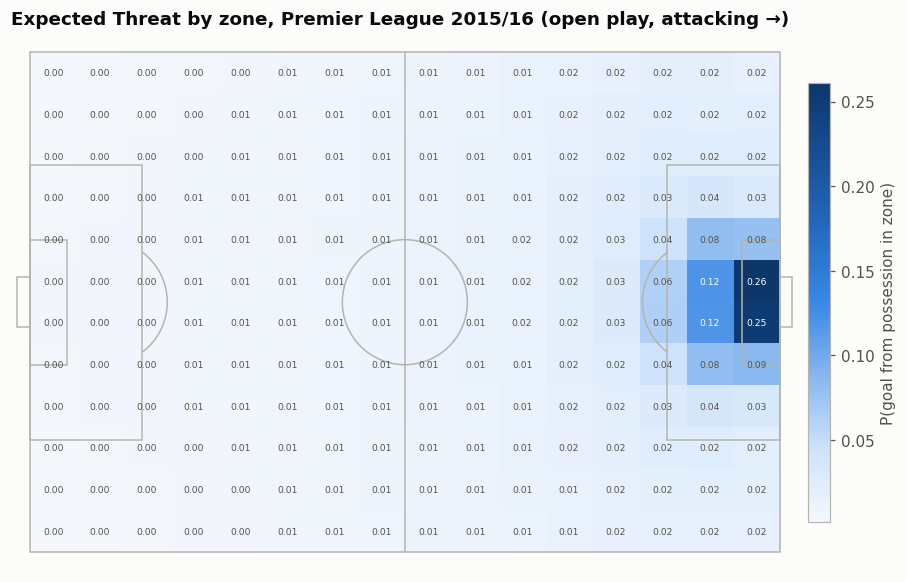

In [3]:
fig, ax = plt.subplots(figsize=(11, 7.4))
im = pitch_heatmap(ax, model.grid, annotate=True)
ax.set_title("Expected Threat by zone, Premier League 2015/16 (open play, attacking →)")
fig.colorbar(im, ax=ax, shrink=0.7, pad=0.01, label="P(goal from possession in zone)")
save(fig, "xt_grid")
plt.show()

In [4]:
grid = model.grid
print(f"Most valuable zone: {grid.max():.3f} (central, edge of the six-yard box)")
print(f"Own half average:   {grid[:, :8].mean():.4f}")
print(f"Left/right symmetry: corr(grid, flipped grid) = {np.corrcoef(grid.ravel(), grid[::-1].ravel())[0, 1]:.3f}")

Most valuable zone: 0.261 (central, edge of the six-yard box)
Own half average:   0.0053
Left/right symmetry: corr(grid, flipped grid) = 0.999


## Why fitting on the whole season matters

An earlier version of this project fitted a fresh xT surface **for every match**, using only that match's ~1,700 actions. That makes zone values noisy, and it also makes them circular: a zone gets a high value in a given match *because* that match's shots came from it, and those values are then used to rate the same match's actions.

To show the size of the problem, we fit a surface on each match on its own and compare it with the season surface.

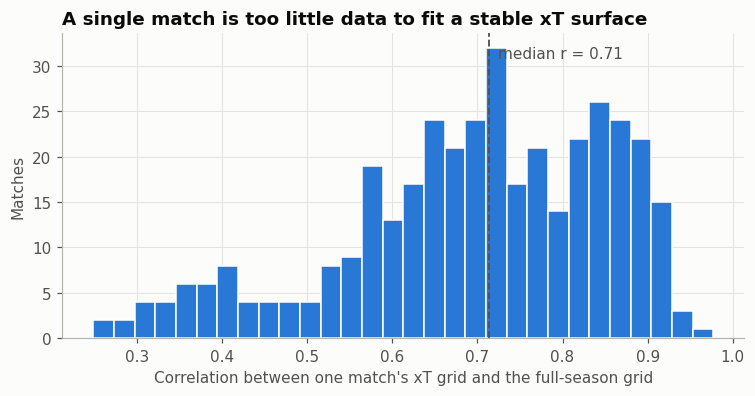

count    380.000
mean       0.697
std        0.158
min        0.249
25%        0.610
50%        0.713
75%        0.828
max        0.977
dtype: float64

In [5]:
season = model.values_
per_match_corr = []
for match_id, match_actions in actions[~actions["set_piece"]].groupby("match_id"):
    single = ExpectedThreat().fit(match_actions).values_
    per_match_corr.append(np.corrcoef(single, season)[0, 1])
per_match_corr = pd.Series(per_match_corr)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(per_match_corr, bins=30, color=SERIES[0], edgecolor="white", linewidth=1)
ax.axvline(per_match_corr.median(), color=TEXT_SECONDARY, lw=1.2, ls="--")
ax.annotate(f"median r = {per_match_corr.median():.2f}", (per_match_corr.median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=TEXT_SECONDARY)
ax.set_title("A single match is too little data to fit a stable xT surface")
ax.set_xlabel("Correlation between one match's xT grid and the full-season grid")
ax.set_ylabel("Matches")
save(fig, "xt_single_match_instability")
plt.show()
per_match_corr.describe()

The median single-match surface correlates only about 0.71 with the season surface, and some matches fall as low as 0.25. Zone values (and so every player's xT) would change a lot depending on which match they were fitted on. The rest of the project uses the single season-level surface.

## Sanity check: who does the model rate?

If the model is right, the players at the top should be the league's best-known creators. The table is restricted to players with at least 900 minutes.

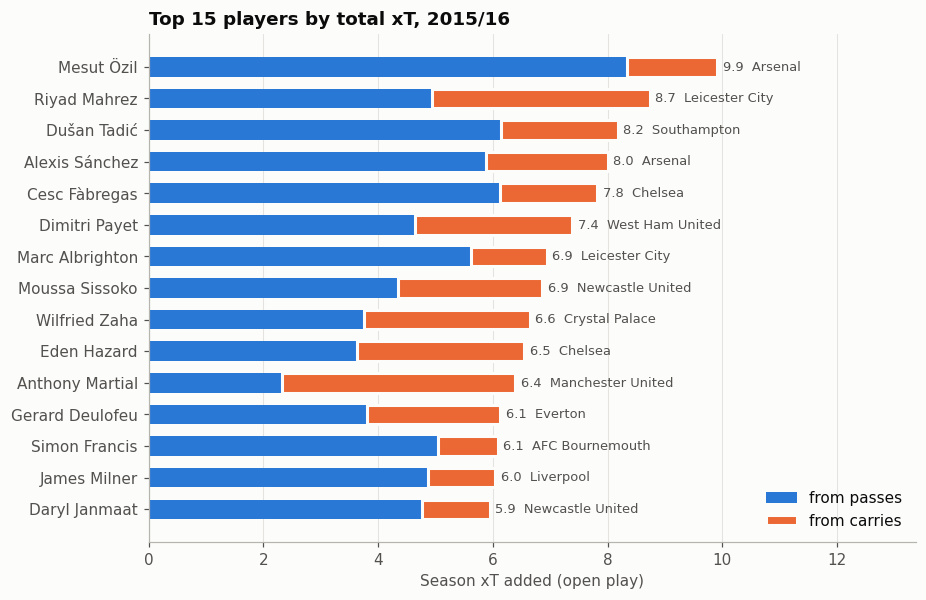

In [6]:
regulars = players[(players["minutes"] >= 900) & (players["position_group"] != "GK")]
top = regulars.nlargest(15, "xt").sort_values("xt")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["player"], top["xt_pass"], color=SERIES[0], height=0.62, label="from passes")
ax.barh(top["player"], top["xt_carry"], left=top["xt_pass"], color=SERIES[1], height=0.62,
        label="from carries", edgecolor="#fcfcfb", linewidth=2)
for y, (total, team) in enumerate(zip(top["xt"], top["team"])):
    ax.text(total + 0.1, y, f"{total:.1f}  {team}", va="center", fontsize=8.5, color=TEXT_SECONDARY)
ax.set_xlim(0, top["xt"].max() * 1.35)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Season xT added (open play)")
ax.set_title("Top 15 players by total xT, 2015/16")
ax.legend(loc="lower right")
save(fig, "top_xt_players")
plt.show()

In [7]:
cols = ["player", "team", "position", "minutes", "xt", "xt_p90", "xt_pass_p90", "xt_carry_p90", "npxg_p90"]
regulars.nlargest(10, "xt_p90")[cols]

,player,team,position,minutes,xt,xt_p90,xt_pass_p90,xt_carry_p90,npxg_p90
250,Gerard Deulofeu,Everton,Right Wing,1446.950,6.134,0.382,0.237,0.144,0.097
136,Dušan Tadić,Southampton,Left Wing,2347.583,8.175,0.313,0.236,0.078,0.230
119,Alexis Sánchez,Arsenal,Left Wing,2518.367,8.001,0.286,0.210,0.076,0.403
47,Mesut Özil,Arsenal,Center Attacking Midfield,3135.267,9.907,0.284,0.240,0.045,0.171
253,Jefferson Montero,Swansea City,Left Wing,1415.417,4.435,0.282,0.153,0.129,0.116
139,Eden Hazard,Chelsea,Left Wing,2311.500,6.546,0.255,0.141,0.114,0.093
51,Riyad Mahrez,Leicester City,Right Midfield,3107.367,8.733,0.253,0.143,0.110,0.216
98,Dimitri Payet,West Ham United,Left Wing,2687.600,7.381,0.247,0.156,0.092,0.170
265,Santi Cazorla,Arsenal,Left Defensive Midfield,1334.933,3.568,0.241,0.172,0.069,0.067
168,Philippe Coutinho,Liverpool,Left Wing,2104.800,5.469,0.234,0.123,0.111,0.305


## Takeaways

* The surface has the expected shape. Value is close to zero in a team's own half, rises slowly through midfield and climbs steeply in the central channel of the penalty area, peaking at **0.26** just outside the six-yard box. It is almost perfectly symmetric left to right (r = 0.999), even though nothing in the model forces that.
* The leaders are the season's recognised creators: **Mesut Özil** (19 assists that season, one short of the Premier League record) leads on total xT, almost all of it from passing. **Riyad Mahrez**, that season's PFA Player of the Year, is second and earns more of his threat by carrying the ball.
* Splitting xT into passes and carries already separates player types: Özil, Fàbregas and Milner from passing; Martial, Zaha and Mahrez from carrying. Notebook 2 builds on this.

**Limitations.** xT values the ball's location only. It ignores how a team got there, defensive pressure and the receiving player's body shape. It is also fitted and applied to the same season: with 655k actions behind 192 zones, any one action's effect on the surface is negligible, but a stricter setup would fit on other seasons.